
# Notebook 01: Logistics Performance EDA

## 1. Business Objective

The objective of this analysis is to evaluate the historical logistics performance of the Olist e-commerce marketplace.

We will investigate order fulfilment performance, delivery outcomes, and the marketplace's ability to meet its estimated delivery commitments.

The analysis will use Python and Pandas to explore the data, calculate business KPIs, identify patterns, and communicate initial findings.

## 2. Key Business Questions

1. How many orders were placed in the marketplace?
2. What proportion of orders were successfully delivered?
3. What proportion of orders were cancelled or unavailable?
4. How effectively does the marketplace meet its estimated delivery commitments?
5. How does order volume change over time?
6. What initial patterns can be identified in logistics performance?

## 3. Analytical Scope

This notebook focuses on:

- Overall order performance.
- Order status distribution.
- Monthly order volume trends.
- Delivery performance overview.
- Initial business findings.

Detailed delivery-delay analysis, customer review analysis, and subsequent-order behaviour will be investigated in separate notebooks.

## 4. Data Source

The analysis uses the Brazilian E-Commerce Public Dataset by Olist.

The data is retrieved from the SQL Server database:

- Database: OlistAnalytics
- Schema: stg
- Primary source table: stg.orders

The staging layer contains typed and standardised data prepared during the earlier data preparation phase.

## 5. Analytical Principles

- Use the approved KPI Dictionary as the source of truth.
- Preserve the original business meaning of the source data.
- Do not interpret missing delivery dates as zero or assume delivery occurred.
- Use calendar dates when comparing actual and estimated delivery dates.
- Report exclusions and missing values transparently.
- Distinguish observed patterns from proven causes.

## 6. Expected Outcome

By the end of this notebook, we aim to establish a clear baseline of marketplace logistics performance and identify areas requiring deeper investigation.



## 2. Python Environment and Library Imports

This section imports the Python libraries required for the logistics performance analysis.

The selected libraries support data manipulation, numerical calculations, data visualisation, and SQL Server connectivity.


In [16]:

# ============================================================
# 2. PYTHON ENVIRONMENT AND LIBRARY IMPORTS
# ============================================================

# Pandas: Used for data manipulation and analysis.
import pandas as pd

# NumPy: Used for numerical calculations.
import numpy as np

# Matplotlib: Used for creating charts and visualisations.
import matplotlib.pyplot as plt

# SQLAlchemy: Used to connect Python with SQL Server.
from sqlalchemy import create_engine, text

# Additional tools for database connection.
import urllib.parse
from getpass import getpass

# Configure Pandas to display all columns in the output.
pd.set_option("display.max_columns", None)

# Configure the default size of charts.
plt.rcParams["figure.figsize"] = (10, 5)

# Display the installed library versions.
print("Python libraries successfully imported!")

print("\nLibrary versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)


Python libraries successfully imported!

Library versions:
Pandas: 3.0.3
NumPy: 2.4.6
Matplotlib: 3.11.0



## 3. SQL Server Connection

This section establishes a connection between Python and the SQL Server database.

The analysis retrieves prepared datasets from the staging schema of the OlistAnalytics database.

Windows Authentication is used to establish the connection without storing a database password in the notebook.


In [17]:
# ============================================================
# 3. SQL SERVER CONNECTION
# ============================================================

import urllib.parse
from getpass import getpass
from sqlalchemy import create_engine, text

# Ask for the local SQL Server instance name privately.
server = getpass("Enter your SQL Server instance name: ")

database = "OlistAnalytics"
driver = "ODBC Driver 18 for SQL Server"

# Build the SQL Server connection string.
connection_string = (
    f"DRIVER={{{driver}}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
    "Encrypt=yes;"
    "TrustServerCertificate=yes;"
)

# Convert the connection string for SQLAlchemy.
connection_url = (
    "mssql+pyodbc:///?odbc_connect="
    + urllib.parse.quote_plus(connection_string)
)

# Create the database engine.
engine = create_engine(connection_url)

# Test the database connection.
try:
    with engine.connect() as connection:
        result = connection.execute(
            text("SELECT DB_NAME() AS database_name")
        )

        database_name = result.scalar()

        print("Connection successful!")
        print("Connected database:", database_name)

except Exception as error:
    print("Connection failed.")
    print("Error:", error)


Enter your SQL Server instance name:  ········


Connection successful!
Connected database: OlistAnalytics



## 4. Data Extraction

This section retrieves the order-level dataset from the SQL Server staging table `stg.orders`.

The extracted data contains order identifiers, order statuses, purchase timestamps, actual delivery timestamps, and estimated delivery dates.

The dataset will serve as the foundation for calculating overall order and logistics performance KPIs.


In [18]:

# ============================================================
# 4. DATA EXTRACTION
# ============================================================

# SQL query to retrieve the required order information.
query = """
SELECT
    order_id,
    order_status,
    order_purchase_timestamp,
    order_delivered_customer_date,
    order_estimated_delivery_date
FROM stg.orders;
"""

# Retrieve the SQL Server data into a Pandas DataFrame.
df_orders = pd.read_sql_query(
    sql=text(query),
    con=engine
)

# Display basic information about the extracted dataset.
print("Dataset successfully retrieved!")
print("Dataset shape:", df_orders.shape)

# Display the first five records.
print("\nFirst five records:")
display(df_orders.head())

# Display column names.
print("\nColumn names:")
print(df_orders.columns.tolist())

# Display column data types.
print("\nColumn data types:")
print(df_orders.dtypes)


Dataset successfully retrieved!
Dataset shape: (99441, 5)

First five records:


,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17



Column names:
['order_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Column data types:
order_id                                    str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object



## 5. Initial Dataset Inspection

Before performing the analysis, we examine the structure and completeness of the extracted dataset.

The inspection focuses on:

- Dataset dimensions (rows and columns).
- Column names and data types.
- Duplicate order identifiers.
- Missing values in each column.

This step helps establish whether the dataset is structurally suitable for the planned logistics performance analysis.


In [19]:

# ============================================================
# 5. INITIAL DATASET INSPECTION
# ============================================================

# 1. Check the number of rows and columns.
print("Dataset dimensions:")
print("Rows:", df_orders.shape[0])
print("Columns:", df_orders.shape[1])


# 2. Inspect column names, data types and non-null values.
print("\nDataset information:")
df_orders.info()


# 3. Check whether order IDs are unique.
print("\nOrder ID validation:")

total_records = len(df_orders)

unique_order_ids = df_orders["order_id"].nunique()

duplicate_order_ids = df_orders["order_id"].duplicated().sum()

print("Total records:", total_records)
print("Unique order IDs:", unique_order_ids)
print("Duplicate order IDs:", duplicate_order_ids)


# 4. Check missing values in each column.
print("\nMissing value analysis:")

missing_values = df_orders.isnull().sum()

missing_summary = pd.DataFrame({
    "missing_values": missing_values,
    "missing_percentage": (
        missing_values / len(df_orders) * 100
    ).round(2)
})

display(missing_summary)


Dataset dimensions:
Rows: 99441
Columns: 5

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   order_status                   99441 non-null  str           
 2   order_purchase_timestamp       99441 non-null  datetime64[us]
 3   order_delivered_customer_date  96476 non-null  datetime64[us]
 4   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](3), str(2)
memory usage: 7.7 MB

Order ID validation:
Total records: 99441
Unique order IDs: 99441
Duplicate order IDs: 0

Missing value analysis:


,missing_values,missing_percentage
order_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00



## 6. Order Status Distribution

This section examines the distribution of orders across their recorded order statuses.

The analysis calculates:

- Number of orders in each status.
- Percentage contribution of each status to total orders.

The results provide an overview of marketplace order outcomes and establish the foundation for subsequent order performance KPI calculations.


In [20]:

# ============================================================
# 6. ORDER STATUS DISTRIBUTION
# ============================================================

# Count the number of orders in each status.
status_counts = df_orders["order_status"].value_counts()

# Calculate the percentage of each status
# relative to the total number of orders.
status_percentages = (
    df_orders["order_status"]
    .value_counts(normalize=True) * 100
)

# Combine counts and percentages into one summary table.
order_status_summary = pd.DataFrame({
    "order_count": status_counts,
    "percentage": status_percentages.round(2)
})

# Display the results.
print("Order Status Distribution:")
display(order_status_summary)

# Verify that all orders are included.
print("Total orders:", order_status_summary["order_count"].sum())

print(
    "Total percentage:",
    order_status_summary["percentage"].sum()
)


Order Status Distribution:


,order_count,percentage
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Total orders: 99441
Total percentage: 99.99999999999999


## 7. Monthly Order Volume Trends

This section examines how order volume changes over time.

Orders are grouped by their purchase month using the order purchase timestamp.

The analysis aims to identify:

- Monthly order volumes.
- Changes in order demand over time.
- Months with relatively high or low order activity.
- Potential trends requiring further investigation.

The analysis describes observed order patterns and does not assume that fluctuations are caused by seasonality or specific business events.


In [21]:
# ============================================================
# 7. MONTHLY ORDER VOLUME TRENDS
# ============================================================

# Extract the purchase month from the order timestamp.
# Format: YYYY-MM (example: 2017-01).
df_orders["purchase_month"] = (
    df_orders["order_purchase_timestamp"].dt.strftime("%Y-%m")
)

# Count the number of orders placed in each month.
monthly_order_counts = (
    df_orders.groupby("purchase_month")
    .size()
    .reset_index(name="order_count")
)

# Display the monthly order volume.
print("Monthly Order Volume:")
display(monthly_order_counts)

# Identify the months with the highest and lowest order volumes.
highest_month = monthly_order_counts.loc[
    monthly_order_counts["order_count"].idxmax()
]

lowest_month = monthly_order_counts.loc[
    monthly_order_counts["order_count"].idxmin()
]

print("\nHighest order volume month:")
print(highest_month)

print("\nLowest order volume month:")
print(lowest_month)


Monthly Order Volume:


,purchase_month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026



Highest order volume month:
purchase_month    2017-11
order_count          7544
Name: 13, dtype: object

Lowest order volume month:
purchase_month    2016-12
order_count             1
Name: 2, dtype: object


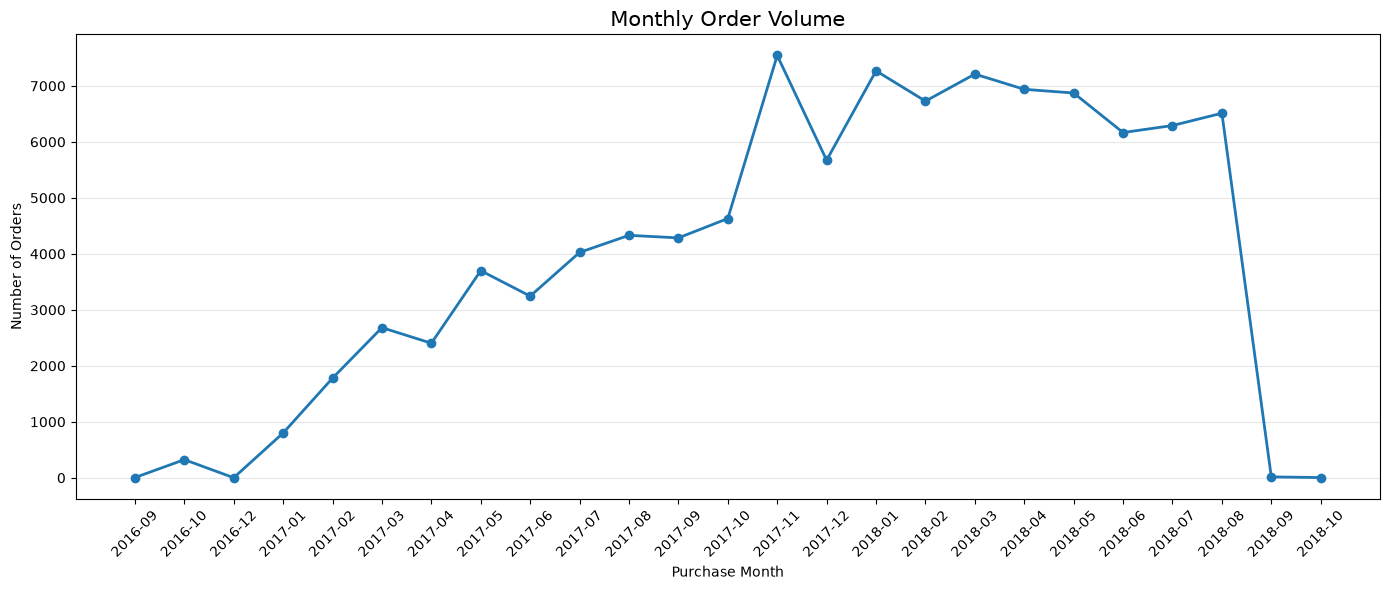

In [22]:

# ============================================================
# 7.1 MONTHLY ORDER VOLUME VISUALISATION
# ============================================================

# Create a line chart to show monthly order volume.
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_order_counts["purchase_month"],
    monthly_order_counts["order_count"],
    marker="o",
    linewidth=2
)

# Add chart title and axis labels.
plt.title("Monthly Order Volume", fontsize=15)
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")

# Rotate month labels for better readability.
plt.xticks(rotation=45)

# Add a grid to improve readability.
plt.grid(axis="y", alpha=0.3)

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()


### Key Observations

- Monthly order volume generally increased during 2017.
- November 2017 recorded the highest monthly order volume, with 7,544 orders.
- Order volumes remained relatively high from January to August 2018.
- September and October 2018 recorded unusually low volumes, suggesting incomplete observation periods.
- The beginning and end of the dataset should be treated cautiously when comparing monthly demand.

These findings describe observed order volumes. They do not establish the causes of demand fluctuations or prove seasonal patterns.

## 8. Overall Delivery Performance

This section provides an initial overview of delivery performance by comparing actual customer delivery dates with estimated delivery dates.

Only delivered orders with both actual and estimated delivery dates are included in the delivery performance calculation.

Delivery performance is classified as follows:

- On-time delivery: Actual delivery date is on or before the estimated delivery date.
- Late delivery: Actual delivery date is after the estimated delivery date.

Calendar dates are used for this comparison, in accordance with the approved KPI methodology.

Orders with missing actual delivery dates are excluded from the calculation, and their exclusion is reported transparently.

In [23]:
# ============================================================
# 8.1 IDENTIFY ELIGIBLE DELIVERED ORDERS
# ============================================================

# Keep only orders with delivered status.
delivered_orders = df_orders[
    df_orders["order_status"] == "delivered"
].copy()

# Keep delivered orders with both actual and estimated
# delivery dates available.
eligible_delivered_orders = delivered_orders[
    delivered_orders["order_delivered_customer_date"].notna()
    & delivered_orders["order_estimated_delivery_date"].notna()
].copy()

# Calculate the number of records at each stage.
total_orders = len(df_orders)
total_delivered_orders = len(delivered_orders)
eligible_orders = len(eligible_delivered_orders)
excluded_orders = total_delivered_orders - eligible_orders

# Display the results.
print("DELIVERY PERFORMANCE ELIGIBILITY")
print("---------------------------------")
print("Total orders:", total_orders)
print("Total delivered orders:", total_delivered_orders)
print("Eligible delivered orders:", eligible_orders)
print("Delivered orders excluded:", excluded_orders)

DELIVERY PERFORMANCE ELIGIBILITY
---------------------------------
Total orders: 99441
Total delivered orders: 96478
Eligible delivered orders: 96470
Delivered orders excluded: 8


In [24]:
# ============================================================
# 8.2 CLASSIFY DELIVERED ORDERS AS ON-TIME OR LATE
# ============================================================

# Extract calendar dates from actual and estimated
# delivery timestamps.
eligible_delivered_orders["actual_delivery_date"] = (
    eligible_delivered_orders[
        "order_delivered_customer_date"
    ].dt.date
)

eligible_delivered_orders["estimated_delivery_date"] = (
    eligible_delivered_orders[
        "order_estimated_delivery_date"
    ].dt.date
)

# Compare actual and estimated delivery dates.
# True  = delivered on time.
# False = delivered late.
eligible_delivered_orders["is_on_time"] = (
    eligible_delivered_orders["actual_delivery_date"]
    <= eligible_delivered_orders["estimated_delivery_date"]
)

# Count on-time and late orders.
delivery_performance = (
    eligible_delivered_orders["is_on_time"]
    .value_counts()
    .rename(index={
        True: "On time",
        False: "Late"
    })
)

# Display the results.
print("DELIVERY PERFORMANCE CLASSIFICATION")
print("------------------------------------")
display(delivery_performance)

DELIVERY PERFORMANCE CLASSIFICATION
------------------------------------


is_on_time
On time    89936
Late        6534
Name: count, dtype: int64

In [25]:
# ============================================================
# 8.3 CALCULATE DELIVERY PERFORMANCE RATES
# ============================================================

# Count on-time and late orders.
on_time_orders = eligible_delivered_orders["is_on_time"].sum()

late_orders = (
    len(eligible_delivered_orders) - on_time_orders
)

# Calculate the on-time and late delivery percentages.
on_time_rate = (
    on_time_orders / len(eligible_delivered_orders) * 100
)

late_delivery_rate = (
    late_orders / len(eligible_delivered_orders) * 100
)

# Create a summary table.
delivery_performance_summary = pd.DataFrame({
    "order_count": [on_time_orders, late_orders],
    "percentage": [
        round(on_time_rate, 2),
        round(late_delivery_rate, 2)
    ]
}, index=["On time", "Late"])

# Display the results.
print("OVERALL DELIVERY PERFORMANCE")
print("-----------------------------")
display(delivery_performance_summary)

# Verify that both percentages add up to 100%.
print(
    "Total percentage:",
    delivery_performance_summary["percentage"].sum()
)

OVERALL DELIVERY PERFORMANCE
-----------------------------


,order_count,percentage
On time,89936,93.23
Late,6534,6.77


Total percentage: 100.0


### Key Findings — Overall Delivery Performance

- Total delivered orders: 96,478.
- Eligible delivered orders: 96,470.
- Delivered orders excluded due to missing actual delivery dates: 8.
- On-time deliveries: 89,936 (93.23%).
- Late deliveries: 6,534 (6.77%).

The analysis indicates that 93.23% of eligible delivered orders arrived on or before their estimated delivery dates, while 6.77% arrived late.

The estimated delivery date is used as an operational SLA proxy because contractual delivery commitments are not available in the dataset.

These results describe overall delivery performance. Further analysis is required to investigate when, where, and across which operational segments delivery delays occur.

## 9. Delivery Lead Time

This section examines the elapsed time between order purchase and actual customer delivery.

Delivery lead time measures how long customers wait to receive their orders, regardless of whether the orders arrived before, on, or after their estimated delivery dates.

The median delivery lead time is used as the primary measure of typical delivery duration, in accordance with the KPI Dictionary.

Delivery lead time is calculated using the actual timestamps to preserve the elapsed duration.

Only delivered orders with valid purchase and actual delivery timestamps are included.

In [26]:
# ============================================================
# 9.1 CALCULATE DELIVERY LEAD TIME
# ============================================================

# Calculate delivery lead time using actual timestamps.
# The difference is expressed in days.
delivered_orders["delivery_lead_time_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Calculate the median delivery lead time.
median_delivery_lead_time = (
    delivered_orders["delivery_lead_time_days"].median()
)

# Display the result.
print("MEDIAN DELIVERY LEAD TIME")
print("----------------------------")
print(
    "Median delivery lead time:",
    round(median_delivery_lead_time, 2),
    "days"
)

MEDIAN DELIVERY LEAD TIME
----------------------------
Median delivery lead time: 10.22 days


In [27]:
# ============================================================
# 9.2 VALIDATE DELIVERY LEAD TIME
# ============================================================

# Count orders with valid delivery lead times.
valid_lead_time_count = (
    delivered_orders["delivery_lead_time_days"].notna().sum()
)

# Count orders with missing delivery lead times.
missing_lead_time_count = (
    delivered_orders["delivery_lead_time_days"].isna().sum()
)

# Check for negative delivery durations.
negative_lead_time_count = (
    delivered_orders["delivery_lead_time_days"] < 0
).sum()

# Display validation results.
print("DELIVERY LEAD TIME VALIDATION")
print("-----------------------------")
print("Total delivered orders:", len(delivered_orders))
print("Valid delivery lead times:", valid_lead_time_count)
print("Missing delivery lead times:", missing_lead_time_count)
print("Negative delivery lead times:", negative_lead_time_count)

DELIVERY LEAD TIME VALIDATION
-----------------------------
Total delivered orders: 96478
Valid delivery lead times: 96470
Missing delivery lead times: 8
Negative delivery lead times: 0


### Key Findings — Delivery Lead Time

- Total delivered orders: 96,478.
- Orders with valid delivery lead times: 96,470.
- Orders excluded due to missing actual delivery timestamps: 8.
- Orders with negative delivery durations: 0.
- Median delivery lead time: 10.22 days.

The median delivery lead time was 10.22 days, meaning that half of the eligible delivered orders had delivery durations at or below this value.

The calculation uses actual purchase and delivery timestamps to measure elapsed time.

Eight delivered orders were excluded because their actual delivery timestamps were unavailable. No negative delivery durations were identified.

This metric describes the typical observed delivery duration and does not independently indicate whether delivery commitments were met.


## 10. Average Late Delivery Delay

This section examines the average number of calendar days by which late orders exceeded their estimated delivery dates.

Only delivered orders classified as late are included.

Late delivery delay is calculated as the difference between the actual delivery calendar date and the estimated delivery calendar date.

The average delay is calculated across late orders only, in accordance with KPI-06 in the KPI Dictionary.

Orders delivered on or before their estimated delivery dates are excluded from this calculation.

In [28]:
# ============================================================
# 10.1 CALCULATE LATE DELIVERY DELAY
# ============================================================

# Select only orders classified as late.
late_delivered_orders = eligible_delivered_orders[
    eligible_delivered_orders["is_on_time"] == False
].copy()

# Calculate the number of calendar days each order was late.
late_delivered_orders["late_delivery_delay_days"] = (
    late_delivered_orders["actual_delivery_date"]
    - late_delivered_orders["estimated_delivery_date"]
).apply(lambda delay: delay.days)

# Calculate the average delay across late orders.
average_late_delivery_delay = (
    late_delivered_orders["late_delivery_delay_days"].mean()
)

# Display the result.
print("AVERAGE LATE DELIVERY DELAY")
print("---------------------------")
print("Late orders:", len(late_delivered_orders))
print(
    "Average late delivery delay:",
    round(average_late_delivery_delay, 2),
    "days"
)

AVERAGE LATE DELIVERY DELAY
---------------------------
Late orders: 6534
Average late delivery delay: 10.62 days


In [29]:
# ============================================================
# 10.2 VALIDATE LATE DELIVERY DELAY
# ============================================================

# Count late orders with valid delay calculations.
valid_delay_count = (
    late_delivered_orders["late_delivery_delay_days"].notna().sum()
)

# Count missing delay calculations.
missing_delay_count = (
    late_delivered_orders["late_delivery_delay_days"].isna().sum()
)

# Check for zero or negative delays.
invalid_delay_count = (
    late_delivered_orders["late_delivery_delay_days"] <= 0
).sum()

# Display validation results.
print("LATE DELIVERY DELAY VALIDATION")
print("------------------------------")
print("Total late orders:", len(late_delivered_orders))
print("Valid delay calculations:", valid_delay_count)
print("Missing delay calculations:", missing_delay_count)
print("Zero or negative delays:", invalid_delay_count)

# Confirm the average delay.
print(
    "Average delay:",
    round(late_delivered_orders["late_delivery_delay_days"].mean(), 2),
    "days"
)

LATE DELIVERY DELAY VALIDATION
------------------------------
Total late orders: 6534
Valid delay calculations: 6534
Missing delay calculations: 0
Zero or negative delays: 0
Average delay: 10.62 days


### Key Findings — Average Late Delivery Delay

- Total late delivered orders: 6,534.
- Orders with valid delay calculations: 6,534.
- Orders with missing delay calculations: 0.
- Orders with zero or negative delay: 0.
- Average late delivery delay: 10.62 calendar days.

The analysis indicates that late delivered orders exceeded their estimated delivery dates by an average of 10.62 calendar days.

All 6,534 late orders had valid positive delay calculations.

This metric considers late orders only and uses calendar-date differences, in accordance with KPI-06 in the KPI Dictionary.

The average delay describes the severity of lateness across affected orders. Further investigation is required to identify the operational and geographical factors associated with these delays.

## 11. Overall Logistics Performance Summary

This section consolidates the key logistics performance indicators calculated throughout this notebook.

The summary provides an overview of order volume, delivery completion, delivery commitment performance, and delivery duration.

All metrics follow the definitions and calculation rules established in the project KPI Dictionary.

The results describe historical performance and provide a baseline for more detailed delivery-delay investigation in the next analysis stage.


In [30]:
# ============================================================
# 11.1 OVERALL LOGISTICS PERFORMANCE SUMMARY
# ============================================================

# Create a summary table containing the key logistics KPIs.
logistics_summary = pd.DataFrame({
    "kpi": [
        "Total Placed Orders",
        "Delivered Order Rate",
        "On-Time Delivery Rate",
        "Late Delivery Rate",
        "Median Delivery Lead Time",
        "Average Late Delivery Delay"
    ],

    "value": [
        total_orders,
        round(
            total_delivered_orders / total_orders * 100, 2
        ),
        round(on_time_rate, 2),
        round(late_delivery_rate, 2),
        round(median_delivery_lead_time, 2),
        round(average_late_delivery_delay, 2)
    ],

    "unit": [
        "orders",
        "%",
        "%",
        "%",
        "days",
        "days"
    ]
})

# Format KPI values for easier readability.
logistics_summary["value"] = logistics_summary.apply(
    lambda row: (
        f"{int(row['value']):,}"
        if row["unit"] == "orders"
        else f"{row['value']:.2f}"
    ),
    axis=1
)

# Display the formatted summary.
display(logistics_summary)

# Display the consolidated KPI summary.
print("OVERALL LOGISTICS PERFORMANCE SUMMARY")
print("--------------------------------------")
display(logistics_summary)

,kpi,value,unit
0,Total Placed Orders,"99,441",orders
1,Delivered Order Rate,97.02,%
2,On-Time Delivery Rate,93.23,%
3,Late Delivery Rate,6.77,%
4,Median Delivery Lead Time,10.22,days
5,Average Late Delivery Delay,10.62,days


OVERALL LOGISTICS PERFORMANCE SUMMARY
--------------------------------------


,kpi,value,unit
0,Total Placed Orders,"99,441",orders
1,Delivered Order Rate,97.02,%
2,On-Time Delivery Rate,93.23,%
3,Late Delivery Rate,6.77,%
4,Median Delivery Lead Time,10.22,days
5,Average Late Delivery Delay,10.62,days


### 11.2 Overall Business Findings

The initial logistics performance analysis provides the following insights:

1. **High delivered order rate:** Approximately 97.02% of all placed orders reached delivered status, indicating that the large majority of orders were successfully delivered.

2. **Generally strong on-time delivery performance:** Among eligible delivered orders, 93.23% arrived on or before the estimated delivery date. However, 6.77% were delivered late, representing 6,534 orders that may require further investigation.

3. **Meaningful delivery delays among late orders:** Late orders experienced an average delay of 10.62 calendar days beyond their estimated delivery dates. This indicates that, although most eligible orders arrived on time, delays could be substantial when they occurred.

4. **Typical customer waiting time:** The median purchase-to-delivery lead time was 10.22 days. This represents the middle delivery duration among delivered orders with valid delivery timestamps.

5. **Data eligibility and limitations:** Eight delivered orders were excluded from the on-time delivery calculation because their actual delivery dates were missing. The estimated delivery date is used as an operational delivery commitment proxy, not as evidence of a contractual service-level agreement.

**Overall conclusion**

The initial results suggest that the marketplace achieved a high delivered order rate and a relatively high on-time delivery rate. Nevertheless, the late delivery rate and average delay indicate opportunities for further investigation.

The next analyses will examine delivery performance across different dimensions, including time periods, geographical areas, sellers, and order characteristics. These investigations will help identify where delivery problems are concentrated rather than relying only on overall averages.
